# Carevora - Cognitive Risk Model (v4 - Drive-persistent results)
**AI-Based Cognitive Wellness Monitoring and Early Cognitive Decline Prediction** (J26-IT-421)

Pipeline: data checks -> resident-level split -> **ACRF feature processing** -> baseline comparison + ablation (GroupKFold CV) -> **single** final test evaluation -> alert threshold -> **SHAP** -> save model.

What changed compared with the first notebook
- The test residents are used **once**, after the model is chosen by cross-validation on training residents only.
- ACRF is now implemented here (`carevora_acrf.py`) instead of being a pre-computed CSV column. It is causal: it uses only the current and earlier assessments of the same resident.
- `*_error_rate` (exactly `1 - accuracy`) and the CSV `acrf_score` (a fixed weighted mean of the five scores) are not used as inputs.
- Results are reported as mean +/- std over folds and with a resident-level bootstrap confidence interval.
- SHAP, an early-warning (next-assessment worsening) experiment, and model saving are included.

> The data is **simulated** (`carevora_cognitive_synthetic_v2.csv`, produced by `generate_dataset.py`). Accuracy here is accuracy on a simulated benchmark, not clinical accuracy.

In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ("shap", "xgboost") if importlib.util.find_spec(p) is None]
if missing:                                   # e.g. on a fresh Google Colab runtime
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", *missing])

In [2]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, shap

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score, roc_auc_score, average_precision_score)
from xgboost import XGBClassifier

# Google Drive persistence: mount Drive and keep dataset/results there across runtime resets.
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/Carevora_Cognitive"
ARTIFACTS_DIR = os.path.join(DRIVE_DIR, "artifacts")
os.makedirs(DRIVE_DIR, exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)


warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
LABELS = ["Low", "Moderate", "High"]            # ordered: 0, 1, 2
DOMAINS = ["memory", "attention", "orientation", "recall", "reasoning"]

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and check the data

In [3]:
# Load the dataset from Google Drive first; if missing, upload it once and save it to Drive.
import os, shutil
DRIVE_CSV = os.path.join(DRIVE_DIR, "carevora_cognitive_synthetic_v2.csv")
CANDIDATES = [
    DRIVE_CSV,
    "carevora_cognitive_synthetic_v2.csv",
    "/content/carevora_cognitive_synthetic_v2.csv",
]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    if csv_name is None:
        raise FileNotFoundError("Please upload carevora_cognitive_synthetic_v2.csv")
    path = os.path.abspath(csv_name)
    shutil.copy2(path, DRIVE_CSV)
    path = DRIVE_CSV
    print("Dataset copied to Google Drive:", DRIVE_CSV)
elif os.path.abspath(path) != os.path.abspath(DRIVE_CSV):
    shutil.copy2(path, DRIVE_CSV)
    path = DRIVE_CSV
    print("Dataset copied to Google Drive:", DRIVE_CSV)

df = (pd.read_csv(path)
        .sort_values(["resident_id", "assessment_number"])
        .reset_index(drop=True))

print("Dataset loaded from:", path)
print("Shape:", df.shape)
print("Residents:", df.resident_id.nunique())
print("Assessments per resident:", df.groupby("resident_id").size().value_counts().to_dict())
print("Missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print("\\nRisk distribution:\\n", df.risk_level.value_counts())

# redundancy checks that justify dropping columns
err_ok = all(np.allclose(df[f"{d}_error_rate"], 1 - df[f"{d}_accuracy"]) for d in DOMAINS)
w = dict(memory=.25, attention=.20, orientation=.20, recall=.20, reasoning=.15)
acrf_ok = np.allclose(df.acrf_score, sum(w[d] * df[f"{d}_score"] for d in DOMAINS))
print("\\nerror_rate == 1 - accuracy for every domain:", err_ok)
print("CSV acrf_score == fixed weighted mean of the 5 scores:", acrf_ok)
df.head()


Shape: (10000, 27)
Residents: 2000
Assessments per resident: {5: 2000}
Missing values: 0 | duplicate rows: 0

Risk distribution:
 risk_level
Moderate    4595
High        2870
Low         2535
Name: count, dtype: int64

error_rate == 1 - accuracy for every domain: True
CSV acrf_score == fixed weighted mean of the 5 scores: True


,resident_id,assessment_number,age,education_years,memory_score,attention_score,orientation_score,recall_score,reasoning_score,acrf_score,...,orientation_error_rate,orientation_response_time,recall_accuracy,recall_error_rate,recall_response_time,reasoning_accuracy,reasoning_error_rate,reasoning_response_time,risk_level,record_source
0,RES_0001,1,87,11,31.254832,34.872126,43.226796,26.668863,30.600938,33.357406,...,0.531056,3.394034,0.253839,0.746161,4.000328,0.321979,0.678021,4.024012,High,synthetic_simulated_v2
1,RES_0001,2,87,11,29.824976,28.910276,40.195284,19.966375,30.516176,29.848058,...,0.578529,3.738528,0.215958,0.784042,4.187402,0.312127,0.687873,3.965179,High,synthetic_simulated_v2
2,RES_0001,3,87,11,21.448201,27.741615,37.813407,18.839866,26.779467,26.257948,...,0.630120,4.020772,0.162424,0.837576,4.640459,0.217309,0.782691,4.000260,High,synthetic_simulated_v2
3,RES_0001,4,87,11,17.974088,23.371828,32.169849,12.391908,22.679090,21.482103,...,0.663387,3.906128,0.144634,0.855366,4.546915,0.231547,0.768453,4.402754,High,synthetic_simulated_v2
4,RES_0001,5,87,11,10.221006,16.138950,27.633103,6.174021,17.331166,15.144141,...,0.703707,4.025556,0.049041,0.950959,4.880027,0.122692,0.877308,4.096356,High,synthetic_simulated_v2


In [4]:
df = df.dropna(subset=["risk_level"]).copy()
df["y"] = df.risk_level.map({l: i for i, l in enumerate(LABELS)}).astype(int)

RAW_FEATURES = (["age", "education_years"]
                + [f"{d}_score" for d in DOMAINS]
                + [f"{d}_accuracy" for d in DOMAINS]
                + [f"{d}_response_time" for d in DOMAINS])

# Resident-level split: all assessments of one resident stay on the same side.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, df.y, groups=df.resident_id))
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
assert not set(train.resident_id) & set(test.resident_id)
print("Train:", len(train), "rows /", train.resident_id.nunique(), "residents")
print("Test :", len(test),  "rows /", test.resident_id.nunique(),  "residents")
print(train.risk_level.value_counts(normalize=True).round(3).to_dict())
print(test.risk_level.value_counts(normalize=True).round(3).to_dict())

Train: 8000 rows / 1600 residents
Test : 2000 rows / 400 residents
{'Moderate': 0.453, 'High': 0.287, 'Low': 0.26}
{'Moderate': 0.486, 'High': 0.288, 'Low': 0.226}


## 2. ACRF - Adaptive Cognitive Risk Fusion

For each resident and assessment *t* (using only assessments up to *t*):

1. **Performance index** per domain: `P_d = score_d - lambda * slowness_d`, where slowness is how many SD the response time is above the training mean (only slower-than-average is penalised).
2. **Personal baseline**: `E_d` = exponentially weighted mean of the resident's own `P_d` history.
3. **Change vs. own past**: `C_d = P_d(t) - E_d(t-1)` (negative = declining).
4. **Adaptive weights**: start from base weights (memory .25, attention .20, orientation .20, recall .20, reasoning .15) and increase the weight of domains that are declining: `w_d ~ base_d * (1 + beta * max(0, -C_d / sd_d))`, then normalise.
5. **Outputs**: `E_d`, `C_d`, fused level `sum(w_d E_d)`, fused change `sum(w_d C_d)`, number of declining domains, weakest domain level.

Only unlabelled statistics (response-time mean/SD, SD of changes) are learned, from the training residents.

**v3 correction:** During model-selection CV, ACRF statistics are fitted separately inside each fold. The held-out test split is still held out by resident. Synthetic performance is not clinical validation.


In [5]:
%%writefile carevora_acrf.py
import numpy as np
import pandas as pd

DOMAINS = ["memory", "attention", "orientation", "recall", "reasoning"]
BASE_WEIGHTS = {"memory": .25, "attention": .20, "orientation": .20, "recall": .20, "reasoning": .15}


class ACRF:
    """Adaptive Cognitive Risk Fusion. Causal: each row uses only the same resident's current/earlier assessments."""

    def __init__(self, base_weights=None, lam=2.0, alpha=0.6, beta=0.5):
        self.base_weights = base_weights or BASE_WEIGHTS
        self.lam, self.alpha, self.beta = lam, alpha, beta

    def _core(self, df):
        rid = df["resident_id"]
        P, E, C = {}, {}, {}
        for d in DOMAINS:
            slow = ((df[f"{d}_response_time"] - self.rt_mean_[d]) / self.rt_std_[d]).clip(lower=0)
            P[d] = df[f"{d}_score"] - self.lam * slow
            E[d] = P[d].groupby(rid).transform(lambda s: s.ewm(alpha=self.alpha, adjust=False).mean())
            prior = E[d].groupby(rid).shift(1)
            C[d] = (P[d] - prior).fillna(0.0)
        return P, E, C

    def fit(self, df):
        self.rt_mean_ = {d: df[f"{d}_response_time"].mean() for d in DOMAINS}
        self.rt_std_ = {d: df[f"{d}_response_time"].std() for d in DOMAINS}
        _, _, C = self._core(df)
        self.change_sd_ = {d: max(C[d][C[d] != 0].std(), 1e-6) for d in DOMAINS}
        return self

    def transform(self, df):
        df = df.sort_values(["resident_id", "assessment_number"])
        P, E, C = self._core(df)
        raw_w = pd.DataFrame({d: self.base_weights[d] * (1 + self.beta * (-C[d] / self.change_sd_[d]).clip(lower=0))
                              for d in DOMAINS})
        w = raw_w.div(raw_w.sum(axis=1), axis=0)
        out = pd.DataFrame(index=df.index)
        for d in DOMAINS:
            out[f"acrf_base_{d}"] = E[d]
            out[f"acrf_change_{d}"] = C[d]
        out["acrf_level"] = sum(w[d] * E[d] for d in DOMAINS)
        out["acrf_change"] = sum(w[d] * C[d] for d in DOMAINS)
        out["acrf_n_declining"] = sum((C[d] < -self.change_sd_[d]).astype(int) for d in DOMAINS)
        out["acrf_weakest_domain"] = pd.concat([E[d] for d in DOMAINS], axis=1).min(axis=1)
        return out.loc[df.index].sort_index()

Overwriting carevora_acrf.py


In [6]:
from carevora_acrf import ACRF

acrf = ACRF().fit(train)
train_f = pd.concat([train, acrf.transform(train)], axis=1)
test_f  = pd.concat([test,  acrf.transform(test)],  axis=1)

ACRF_FEATURES = list(acrf.transform(train.head(10)).columns)   # only the features produced by ACRF (not the CSV acrf_score)
FEATURE_SETS = {
    "A: raw features":        RAW_FEATURES,
    "B: raw + ACRF":          RAW_FEATURES + ACRF_FEATURES,
    "C: ACRF only (+demog.)": ["age", "education_years"] + ACRF_FEATURES,
}
print(len(ACRF_FEATURES), "ACRF features:", ACRF_FEATURES)
print("\nCorrelation of fused ACRF level with risk (train):",
      round(train_f[["acrf_level", "y"]].corr().iloc[0, 1], 3))

14 ACRF features: ['acrf_base_memory', 'acrf_change_memory', 'acrf_base_attention', 'acrf_change_attention', 'acrf_base_orientation', 'acrf_change_orientation', 'acrf_base_recall', 'acrf_change_recall', 'acrf_base_reasoning', 'acrf_change_reasoning', 'acrf_level', 'acrf_change', 'acrf_n_declining', 'acrf_weakest_domain']

Correlation of fused ACRF level with risk (train): -0.921


## 3. Baselines and ablation (GroupKFold on training residents only)

In [ ]:
def make_pipe(model):
    return Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("model", model)
    ])

MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "SVM (RBF)": SVC(kernel="rbf", C=3.0, probability=True, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.9,
                             colsample_bytree=0.8, reg_lambda=2.0, eval_metric="mlogloss",
                             tree_method="hist", random_state=SEED, n_jobs=1),
}

# IMPORTANT: ACRF is refitted separately inside each fold.
# The held-out fold's response-time/change statistics are never used to fit ACRF.
cv = GroupKFold(n_splits=5)
rows = []

for fold, (fit_idx, val_idx) in enumerate(cv.split(train, train.y, groups=train.resident_id), start=1):
    fold_train = train.iloc[fit_idx].copy().reset_index(drop=True)
    fold_val = train.iloc[val_idx].copy().reset_index(drop=True)

    fold_acrf = ACRF().fit(fold_train)
    fold_train_f = pd.concat([fold_train, fold_acrf.transform(fold_train)], axis=1)
    fold_val_f = pd.concat([fold_val, fold_acrf.transform(fold_val)], axis=1)

    fold_acrf_features = list(fold_acrf.transform(fold_train.head(10)).columns)
    fold_feature_sets = {
        "A: raw features": RAW_FEATURES,
        "B: raw + ACRF": RAW_FEATURES + fold_acrf_features,
        "C: ACRF only (+demog.)": ["age", "education_years"] + fold_acrf_features,
    }

    for fs_name, cols in fold_feature_sets.items():
        for m_name, model in MODELS.items():
            fitted = make_pipe(clone(model))
            fitted.fit(fold_train_f[cols], fold_train_f.y)
            pred = fitted.predict(fold_val_f[cols])
            rows.append({
                "Fold": fold,
                "Feature set": fs_name,
                "Model": m_name,
                "Accuracy": accuracy_score(fold_val_f.y, pred),
                "Macro-F1": f1_score(fold_val_f.y, pred, average="macro", zero_division=0)
            })
    print(f"Completed fold {fold}/5")

fold_results = pd.DataFrame(rows)
cv_table = (fold_results.groupby(["Feature set", "Model"])
            .agg(**{"CV accuracy": ("Accuracy", "mean"),
                    "acc std": ("Accuracy", "std"),
                    "CV macro-F1": ("Macro-F1", "mean"),
                    "F1 std": ("Macro-F1", "std")})
            .reset_index())
print(cv_table.sort_values("CV macro-F1", ascending=False).reset_index(drop=True).round(4).to_string())


In [8]:
# Ablation summary: best CV macro-F1 per feature set
abl = cv_table.loc[cv_table.groupby("Feature set")["CV macro-F1"].idxmax()].reset_index(drop=True)
print(abl.round(4).to_string())

              Feature set                Model  CV accuracy  acc std  CV macro-F1  F1 std
0         A: raw features  Logistic Regression       0.9570   0.0083       0.9576  0.0080
1           B: raw + ACRF        Random Forest       0.9621   0.0065       0.9626  0.0062
2  C: ACRF only (+demog.)  Logistic Regression       0.9614   0.0066       0.9620  0.0065


## 4. Model selection rule (decided on CV only)

Pick the feature set + model with the best cross-validated macro-F1. If a tree-based model is within **one standard deviation** of the best, prefer it because SHAP's TreeExplainer is exact and fast for it.

In [9]:
best = cv_table.sort_values("CV macro-F1", ascending=False).iloc[0]
close = cv_table[(cv_table["Feature set"] == best["Feature set"]) &
                 (cv_table["CV macro-F1"] >= best["CV macro-F1"] - best["F1 std"]) &
                 (cv_table["Model"].isin(["XGBoost", "Random Forest", "Decision Tree"]))]
chosen = close.sort_values("CV macro-F1", ascending=False).iloc[0] if len(close) else best
FS_NAME, MODEL_NAME = chosen["Feature set"], chosen["Model"]
FEATURES = FEATURE_SETS[FS_NAME]
print(f"Best by CV         : {best['Model']} on '{best['Feature set']}' (F1 {best['CV macro-F1']:.4f})")
print(f"Selected for use   : {MODEL_NAME} on '{FS_NAME}' (F1 {chosen['CV macro-F1']:.4f})")

Best by CV         : Random Forest on 'B: raw + ACRF' (F1 0.9626)
Selected for use   : Random Forest on 'B: raw + ACRF' (F1 0.9626)


## 5. Final evaluation on held-out test residents (used once)

FINAL MODEL: Random Forest | features: B: raw + ACRF
-------------------------------------------------------
Accuracy         : 0.9680
Macro precision  : 0.9666
Macro recall     : 0.9687
Macro F1         : 0.9676
Quadratic kappa  : 0.9687
High-risk recall : 0.9688

               precision    recall  f1-score   support

         Low     0.9442    0.9713    0.9576       453
    Moderate     0.9680    0.9660    0.9670       971
        High     0.9876    0.9688    0.9781       576

    accuracy                         0.9680      2000
   macro avg     0.9666    0.9687    0.9676      2000
weighted avg     0.9683    0.9680    0.9681      2000

Accuracy 95% bootstrap CI (by resident): [0.9585, 0.9770]


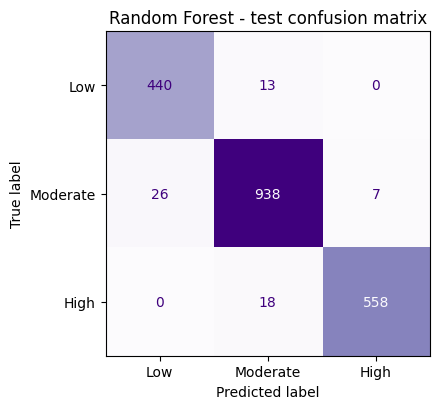

In [10]:
final_model = make_pipe(clone(MODELS[MODEL_NAME])).fit(train_f[FEATURES], train_f.y)
proba_te = final_model.predict_proba(test_f[FEATURES])
pred_te = proba_te.argmax(axis=1)
y_te = test_f.y.values

print(f"FINAL MODEL: {MODEL_NAME} | features: {FS_NAME}")
print("-" * 55)
print(f"Accuracy         : {accuracy_score(y_te, pred_te):.4f}")
print(f"Macro precision  : {precision_score(y_te, pred_te, average='macro'):.4f}")
print(f"Macro recall     : {recall_score(y_te, pred_te, average='macro'):.4f}")
print(f"Macro F1         : {f1_score(y_te, pred_te, average='macro'):.4f}")
print(f"Quadratic kappa  : {cohen_kappa_score(y_te, pred_te, weights='quadratic'):.4f}")
print(f"High-risk recall : {recall_score(y_te == 2, pred_te == 2):.4f}")
print("\n", classification_report(y_te, pred_te, target_names=LABELS, digits=4))

# Resident-level bootstrap CI (resamples residents, not rows)
correct = (pred_te == y_te).astype(float)
codes, uniq = pd.factorize(test_f.resident_id)
n_res = len(uniq)
sum_c = np.bincount(codes, weights=correct, minlength=n_res)
cnt = np.bincount(codes, minlength=n_res)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    s = rng.integers(0, n_res, n_res)
    boot.append(sum_c[s].sum() / cnt[s].sum())
print(f"Accuracy 95% bootstrap CI (by resident): [{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}]")

cm = confusion_matrix(y_te, pred_te, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title(f"{MODEL_NAME} - test confusion matrix")
plt.tight_layout(); plt.savefig(os.path.join(ARTIFACTS_DIR, "confusion_matrix_test.png"), dpi=160); plt.show()

In [11]:
# Reporting table for the proposal: every baseline on the same held-out test residents
# (reporting only - NOT used to choose the model).
rows = []
for fs_name in ["A: raw features", "B: raw + ACRF"]:
    cols = FEATURE_SETS[fs_name]
    for m_name, model in MODELS.items():
        p = make_pipe(clone(model)).fit(train_f[cols], train_f.y).predict(test_f[cols])
        rows.append({"Feature set": fs_name, "Model": m_name,
                     "Accuracy": accuracy_score(y_te, p),
                     "Precision (macro)": precision_score(y_te, p, average="macro"),
                     "Recall (macro)": recall_score(y_te, p, average="macro"),
                     "F1 (macro)": f1_score(y_te, p, average="macro"),
                     "High recall": recall_score(y_te == 2, p == 2)})
test_table = pd.DataFrame(rows)
print(test_table.round(4).to_string())

acc_by_t = pd.Series(correct, index=test_f.assessment_number.values).groupby(level=0).mean().round(4)
print("\nAccuracy by assessment number (more history -> better personal baseline):")
print(acc_by_t.to_dict())

       Feature set                Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  High recall
0  A: raw features  Logistic Regression    0.9620             0.9618          0.9613      0.9615       0.9618
1  A: raw features        Decision Tree    0.9505             0.9499          0.9514      0.9505       0.9444
2  A: raw features        Random Forest    0.9615             0.9601          0.9628      0.9613       0.9583
3  A: raw features            SVM (RBF)    0.9550             0.9542          0.9543      0.9542       0.9601
4  A: raw features              XGBoost    0.9625             0.9608          0.9638      0.9622       0.9635
5    B: raw + ACRF  Logistic Regression    0.9625             0.9630          0.9607      0.9618       0.9635
6    B: raw + ACRF        Decision Tree    0.9615             0.9599          0.9620      0.9609       0.9670
7    B: raw + ACRF        Random Forest    0.9680             0.9666          0.9687      0.9676       0.9688
8    B: ra

## 6. Caregiver alert threshold (chosen on out-of-fold predictions, not on test)

Missing a High-risk resident is worse than a false alarm, so an alert fires when `P(High)` is above a threshold. The threshold is the highest value that keeps out-of-fold High recall >= 0.97 on the training residents.

In [12]:
# Leakage-controlled out-of-fold probabilities: refit ACRF inside each fold.
# This prevents validation residents from contributing to ACRF fit statistics.
oof = np.full((len(train), len(LABELS)), np.nan, dtype=float)
for fit_idx, val_idx in cv.split(train, train.y, groups=train.resident_id):
    fold_train = train.iloc[fit_idx].copy().reset_index(drop=True)
    fold_val = train.iloc[val_idx].copy().reset_index(drop=True)
    fold_acrf = ACRF().fit(fold_train)
    fold_train_f = pd.concat([fold_train, fold_acrf.transform(fold_train)], axis=1)
    fold_val_f = pd.concat([fold_val, fold_acrf.transform(fold_val)], axis=1)
    fold_model = make_pipe(clone(MODELS[MODEL_NAME]))
    fold_model.fit(fold_train_f[FEATURES], fold_train_f.y)
    fold_proba = fold_model.predict_proba(fold_val_f[FEATURES])
    # Align predicted probability columns to class labels 0, 1, 2.
    for j, cls in enumerate(fold_model.named_steps["model"].classes_):
        oof[val_idx, int(cls)] = fold_proba[:, j]

if np.isnan(oof).any():
    raise RuntimeError("Some training rows did not receive out-of-fold predictions.")

is_high = (train.y == 2).values
TARGET_RECALL, ALERT_THRESHOLD = 0.97, 0.5
for t in np.arange(0.50, 0.04, -0.01):
    if recall_score(is_high, oof[:, 2] >= t, zero_division=0) >= TARGET_RECALL:
        ALERT_THRESHOLD = round(float(t), 2); break
print("Leakage-controlled alert threshold on P(High):", ALERT_THRESHOLD)
print("Threshold selected using training-only out-of-fold predictions.")

alert = proba_te[:, 2] >= ALERT_THRESHOLD
print(f"Test High recall    : {recall_score(y_te == 2, alert, zero_division=0):.4f}")
print(f"Test High precision : {precision_score(y_te == 2, alert, zero_division=0):.4f}")
print(f"Alerts raised       : {alert.mean():.1%} of assessments (High prevalence {np.mean(y_te == 2):.1%})")

Alert threshold on P(High): 0.48
Test High recall    : 0.9688
Test High precision : 0.9876
Alerts raised       : 28.2% of assessments (High prevalence 28.8%)


## 7. Explainable AI - SHAP

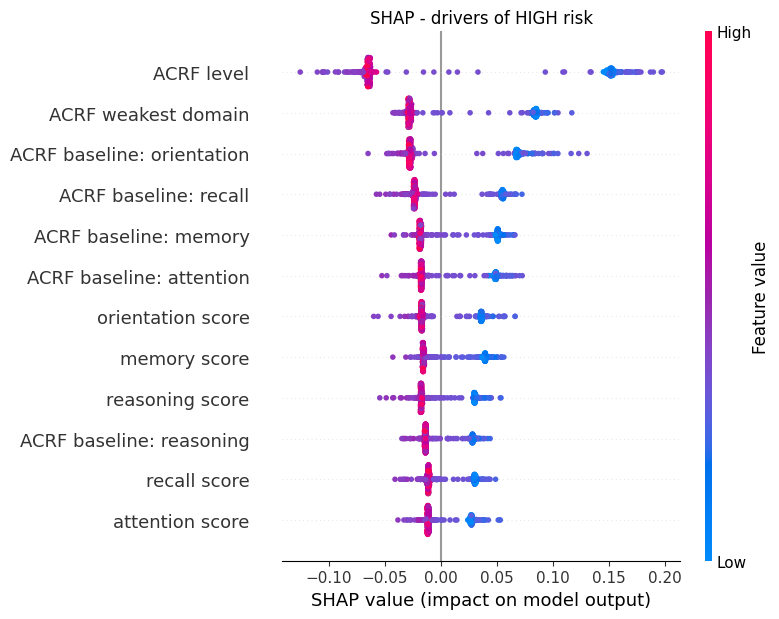

Mean |SHAP| for High-risk (top 10):
 acrf_level               0.0908
acrf_weakest_domain      0.0438
acrf_base_orientation    0.0409
acrf_base_recall         0.0325
acrf_base_memory         0.0276
acrf_base_attention      0.0269
orientation_score        0.0231
memory_score             0.0222
reasoning_score          0.0213
acrf_base_reasoning      0.0180
dtype: float64


In [13]:
PRETTY = lambda n: (n.replace("acrf_base_", "ACRF baseline: ").replace("acrf_change_", "ACRF change: ")
                     .replace("acrf_", "ACRF ").replace("_", " ").replace("response time", "response time (s)"))

def shap_for_class(sv, k):
    if isinstance(sv, list): return np.asarray(sv[k])
    sv = np.asarray(sv)
    return sv[:, :, k] if sv.ndim == 3 else sv

prep = final_model[:-1]                         # imputer + scaler
clf = final_model.named_steps["model"]
X_bg = pd.DataFrame(prep.transform(train_f[FEATURES].sample(500, random_state=SEED)), columns=FEATURES)
sample = test_f[FEATURES].sample(min(600, len(test_f)), random_state=SEED)
X_ex = pd.DataFrame(prep.transform(sample), columns=FEATURES)

if hasattr(clf, "feature_importances_"):
    explainer = shap.TreeExplainer(clf)
else:
    explainer = shap.Explainer(clf.predict_proba, X_bg)
sv = explainer.shap_values(X_ex) if hasattr(explainer, "shap_values") else explainer(X_ex).values
sv_high = shap_for_class(sv, 2)

plt.figure()
shap.summary_plot(sv_high, X_ex.rename(columns=PRETTY), show=False, max_display=12)
plt.title("SHAP - drivers of HIGH risk"); plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS_DIR, "shap_high_risk.png"), dpi=160, bbox_inches="tight"); plt.show()

imp = pd.Series(np.abs(sv_high).mean(0), index=FEATURES).sort_values(ascending=False)
print("Mean |SHAP| for High-risk (top 10):\n", imp.head(10).round(4))

In [14]:
def caregiver_explanation(model, row, top_k=3):
    """Plain-language explanation for one assessment (row = one-row DataFrame with FEATURES)."""
    p = model.predict_proba(row[FEATURES])[0]
    k = int(p.argmax())
    xs = pd.DataFrame(model[:-1].transform(row[FEATURES]), columns=FEATURES)
    s = shap_for_class(explainer.shap_values(xs), k)[0]
    order = np.argsort(-s)[:top_k]
    reasons = [f"{PRETTY(FEATURES[i])} = {row[FEATURES[i]].iloc[0]:.1f}" for i in order if s[i] > 0]
    return {"risk": LABELS[k], "probabilities": {l: float(round(v, 3)) for l, v in zip(LABELS, p)}, "main_factors": reasons}

# one High-risk and one Low-risk test assessment as examples
for lab in (2, 0):
    r = test_f[test_f.y == lab].iloc[[0]]
    print(f"True: {LABELS[lab]:9s} ->", caregiver_explanation(final_model, r))

True: High      -> {'risk': 'High', 'probabilities': {'Low': 0.0, 'Moderate': 0.0, 'High': 1.0}, 'main_factors': ['ACRF level = 33.2', 'ACRF weakest domain = 25.2', 'ACRF baseline: orientation = 44.5']}
True: Low       -> {'risk': 'Low', 'probabilities': {'Low': 0.728, 'Moderate': 0.268, 'High': 0.004}, 'main_factors': ['ACRF level = 72.5', 'ACRF weakest domain = 69.1', 'ACRF baseline: recall = 69.3']}


## 8. Early-warning experiment: will risk worsen at the next assessment?

The model above classifies the *current* risk level. "Early decline prediction" also needs a forward-looking target. Here: for residents not yet High, predict whether the **next** assessment is a higher risk level, using only information up to the current assessment.

In [ ]:
def next_worse(frame):
    f = frame.sort_values(["resident_id", "assessment_number"]).copy()
    f["next_y"] = f.groupby("resident_id").y.shift(-1)
    f = f.dropna(subset=["next_y"])
    # Evaluate worsening only for residents not already High.
    f = f[f.y < 2].copy()
    f["worse_next"] = (f.next_y > f.y).astype(int)
    return f

tr_w, te_w = next_worse(train_f), next_worse(test_f)
print("Worsening rate - train: %.3f | test: %.3f" % (tr_w.worse_next.mean(), te_w.worse_next.mean()))

# Do NOT use the true current risk label ('y') as a predictor.
# The model receives only measurable assessment inputs and optional ACRF features.
ew_cols = {
    "raw assessment features": RAW_FEATURES,
    "raw + ACRF features": RAW_FEATURES + ACRF_FEATURES
}
rows = []
for name, cols in ew_cols.items():
    for m_name in ["Logistic Regression", "XGBoost"]:
        m = make_pipe(clone(MODELS[m_name]))
        if m_name == "Logistic Regression":
            m.set_params(model__class_weight="balanced")
        m.fit(tr_w[cols], tr_w.worse_next)
        pr = m.predict_proba(te_w[cols])[:, 1]
        rows.append({
            "Features": name, "Model": m_name,
            "ROC-AUC": roc_auc_score(te_w.worse_next, pr),
            "PR-AUC": average_precision_score(te_w.worse_next, pr)
        })
ew = pd.DataFrame(rows)
ew.to_csv(os.path.join(ARTIFACTS_DIR, "early_warning_results.csv"), index=False)
print(ew.round(3).to_string())
print("Chance PR-AUC = worsening rate = %.3f" % te_w.worse_next.mean())


## 9. Save the model for the Carevora backend

In [16]:
import shutil\nos.makedirs(ARTIFACTS_DIR, exist_ok=True)
bundle = {"model": final_model, "acrf": acrf, "features": FEATURES, "labels": LABELS,
          "alert_threshold": ALERT_THRESHOLD, "model_name": MODEL_NAME, "feature_set": FS_NAME}
joblib.dump(bundle, os.path.join(ARTIFACTS_DIR, "carevora_cognitive_model.joblib"))

cv_table.to_csv(os.path.join(ARTIFACTS_DIR, "cv_results.csv"), index=False)
test_table.to_csv(os.path.join(ARTIFACTS_DIR, "test_results.csv"), index=False)
json.dump({"model": MODEL_NAME, "feature_set": FS_NAME, "alert_threshold": ALERT_THRESHOLD,
           "test_accuracy": float(accuracy_score(y_te, pred_te)),
           "test_macro_f1": float(f1_score(y_te, pred_te, average="macro")),
           "test_high_recall": float(recall_score(y_te == 2, pred_te == 2))},
          open(os.path.join(ARTIFACTS_DIR, "summary.json"), "w"), indent=2)

def predict_resident(history, bundle):
    """history: DataFrame with one resident's assessments (raw columns). Scores the latest assessment."""
    h = history.sort_values("assessment_number").copy()
    h = pd.concat([h, bundle["acrf"].transform(h)], axis=1)
    last = h.iloc[[-1]]
    p = bundle["model"].predict_proba(last[bundle["features"]])[0]
    k = int(p.argmax())
    return {"risk": bundle["labels"][k], "probabilities": {l: float(round(v, 3)) for l, v in zip(bundle["labels"], p)},
            "caregiver_alert": bool(p[2] >= bundle["alert_threshold"])}

# reload test
loaded = joblib.load(os.path.join(ARTIFACTS_DIR, "carevora_cognitive_model.joblib"))
rid = test.resident_id.iloc[0]
print(rid, predict_resident(test[test.resident_id == rid], loaded))
shutil.copy2("carevora_acrf.py", os.path.join(DRIVE_DIR, "carevora_acrf.py"))\nprint("Model and results saved to:", ARTIFACTS_DIR)

RES_0024 {'risk': 'Moderate', 'probabilities': {'Low': 0.004, 'Moderate': 0.994, 'High': 0.002}, 'caregiver_alert': False}
Saved to ./artifacts
